# 🛒 Texas Supermarket Chain — Retail Sales & Customer Analytics

**Author:** Abrar Ahmed Syed · [GitHub](https://github.com/Abuabrar09) · [LinkedIn](https://www.linkedin.com/in/abrar313) · [Kaggle](https://www.kaggle.com/abrarahmedsyed313)

**Tools:** Python (pandas, NumPy), SQL (SQLite window functions & CTEs), Matplotlib / Seaborn

---

## 1. Business Problem

*FreshMart Texas* is a 5-store regional supermarket chain (Houston, Dallas, Austin, San Antonio, Fort Worth). Leadership is planning the 2026 budget and has asked the analytics team five questions:

1. **How is the business performing?** Revenue, gross margin, traffic and basket size for 2024 vs 2025.
2. **When do customers shop?** Which days, hours and seasons drive traffic, so staffing can match demand.
3. **What sells and what makes money?** Which categories drive revenue vs. profit, and which stores over/under-perform.
4. **Who are our customers?** How loyal are loyalty-program members, how quickly do new members drop off, and which segments need attention.
5. **Do our promotions and product placement work?** Which products are bought together, and do weekly promotions actually create profit?


## ⭐ Key Findings at a Glance

| Area | Finding |
|---|---|
| **Growth** | Revenue +9.2% YoY, but gross profit only +6.0% — margin fell 0.9 pts as supplier costs outpaced shelf prices |
| **Promotions** | ~80% of promo weeks *lose* gross profit; Meat, Dairy and Beverage deals lose money every time |
| **Customers** | Loyalty members = 35% of receipts but 48% of revenue (basket $66 vs $40); 355 high-value members are at risk of churning |
| **Retention** | Only 52% of new members are still active after 6 months, 34% after 12 |
| **Products** | Deli & Bakery are 16% of sales but 25% of profit; strong Texas meal affinities (fajitas + tortillas, brisket + BBQ sauce) |
| **Operations** | Saturday traffic is +41% vs average, Thanksgiving Eve is ~2× a normal day; storm closure caught automatically by anomaly detection |

**Skills demonstrated:** data cleaning & validation · relational joins · KPI design · time-series & seasonality · anomaly detection · RFM segmentation · cohort retention · market basket analysis (support / confidence / lift) · promotion ROI · SQL window functions & CTEs · data storytelling

## 2. About the Data

The dataset is a **simulated** two-year point-of-sale (POS) extract (Jan 2024 – Dec 2025) built to mirror how a real grocery POS system stores data: five relational tables, realistic seasonality, holiday spikes, product affinities, promotions, price inflation, a weather-related store closure, and deliberate data-quality issues to clean.
To keep the notebook fast in a free Colab session, the simulation produces a **representative sample of receipts** (~158K receipts, ~1.1M line items) rather than every checkout, so absolute dollar totals are smaller than a real chain's. The analysis therefore focuses on **ratios, mix, trends and growth rates**, which are what drive decisions.
The generator is included below with a fixed random seed, so every number in this notebook is **fully reproducible** in Google Colab with no file uploads.

| Table | Grain | Key columns |
|---|---|---|
| `stores` | one row per store | store_id, city, sq_ft |
| `products` | one row per SKU | product_id, category, list price |
| `customers` | one row per loyalty member | customer_id, home_store, signup_date |
| `transactions` | one row per checkout (receipt) | txn_id, store_id, customer_id (blank = non-member), datetime, payment |
| `transaction_items` | one row per product on a receipt | txn_id, product_id, quantity, unit_price, unit_cost, discount_pct |

## 3. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import matplotlib.dates as mdates
import sqlite3
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# One consistent, colorblind-tested palette for every chart
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
PALETTE = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
GRAY = "#8a8985"

sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams.update({
    "figure.figsize": (11, 4.8), "figure.dpi": 110,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e5e1", "grid.linewidth": 0.8, "axes.edgecolor": "#b8b7b2",
    "legend.frameon": False,
})
usd = mtick.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M" if abs(x) >= 1e6 else f"${x/1e3:.0f}K" if abs(x) >= 1e3 else f"${x:,.0f}")
print("Libraries loaded ✔")

Libraries loaded ✔


## 4. Generate the POS Dataset

This cell builds the five tables. Skip it if you only care about the analysis — every later section starts from the tables it produces.
Patterns built into the simulation (that the analysis should *discover*, not assume): weekly & seasonal traffic, holidays, product affinities, weekly promotions, member vs. non-member behaviour, member churn, 2025 price/cost inflation, and a 3-day weather closure at one store.

In [2]:
rng = np.random.default_rng(42)
START, END = pd.Timestamp("2024-01-01"), pd.Timestamp("2025-12-31")
days = pd.date_range(START, END, freq="D")

# ---------- stores ----------
stores = pd.DataFrame({
    "store_id":   [101, 102, 103, 104, 105],
    "store_name": ["Katy", "Plano", "Round Rock", "Stone Oak", "Keller"],
    "city":       ["Houston", "Dallas", "Austin", "San Antonio", "Fort Worth"],
    "sq_ft":      [42000, 38000, 30000, 34000, 26000],
    "opened":     pd.to_datetime(["2015-03-01", "2017-06-15", "2019-09-01", "2018-04-20", "2021-11-05"]),
})
store_traffic = {101: 1.25, 102: 1.15, 103: 1.05, 104: 0.85, 105: 0.70}   # relative customer traffic

# ---------- products ----------
catalog = {
 "Produce": [("Bananas (lb)",0.69),("Apples Gala (lb)",1.99),("Avocados",1.25),("Tomatoes (lb)",1.79),("Onions Yellow (lb)",1.09),
             ("Potatoes Russet 5lb",4.49),("Strawberries 1lb",3.99),("Lettuce Romaine",2.29),("Limes",0.39),("Cilantro Bunch",0.89),
             ("Carrots 2lb",2.49),("Spinach 10oz",3.49),("Jalapenos (lb)",1.49),("Grapes Red (lb)",2.99),("Oranges 4lb Bag",5.99)],
 "Dairy & Eggs": [("Whole Milk 1 Gal",3.89),("2% Milk 1 Gal",3.79),("Large Eggs 12ct",3.49),("Butter Salted 1lb",4.99),("Cheddar Shredded 8oz",3.29),
             ("Greek Yogurt 32oz",5.99),("Sour Cream 16oz",2.49),("Coffee Creamer 32oz",4.79),("Mozzarella 16oz",4.49),("Cream Cheese 8oz",2.79)],
 "Bakery": [("White Bread Loaf",2.49),("Wheat Bread Loaf",2.99),("Hamburger Buns 8ct",2.79),("Hot Dog Buns 8ct",2.79),("Flour Tortillas 20ct",3.49),
             ("Corn Tortillas 30ct",2.29),("Bagels 6ct",3.99),("Croissants 4ct",4.99),("Birthday Cake 8in",18.99),("Kolaches 6ct",6.49)],
 "Meat & Seafood": [("Ground Beef 80/20 (lb)",5.49),("Chicken Breast (lb)",3.99),("Chicken Thighs (lb)",2.49),("Ribeye Steak (lb)",14.99),
             ("Pork Chops (lb)",3.99),("Bacon 16oz",6.99),("Brisket (lb)",5.99),("Salmon Fillet (lb)",10.99),("Shrimp 2lb Frozen",15.99),
             ("Breakfast Sausage 16oz",4.49),("Fajita Beef (lb)",8.99),("Hot Dogs 8ct",3.49)],
 "Beverages": [("Bottled Water 24pk",4.99),("Cola 12pk",7.49),("Orange Juice 52oz",4.29),("Ground Coffee 12oz",8.99),("Sweet Tea 1 Gal",2.99),
             ("Sports Drink 8pk",6.99),("Sparkling Water 8pk",4.79),("Energy Drink 4pk",8.49),("Beer 12pk",15.99),("Red Wine 750ml",11.99)],
 "Snacks": [("Tortilla Chips",3.99),("Potato Chips",4.29),("Salsa 16oz",3.49),("Queso Dip 15oz",4.49),("Cookies Chocolate Chip",3.99),
             ("Granola Bars 12ct",4.99),("Mixed Nuts 16oz",8.99),("Popcorn 6pk",3.79),("Crackers",3.49),("Candy Bar",1.49)],
 "Frozen": [("Frozen Pizza",6.49),("Ice Cream 1.5qt",5.49),("Frozen Vegetables 16oz",1.99),("Frozen Burritos 8ct",7.99),("Frozen Waffles",3.29),
             ("Chicken Nuggets 2lb",8.99),("French Fries 32oz",4.29),("Frozen Meals",3.99)],
 "Pantry": [("Spaghetti 16oz",1.49),("Pasta Sauce 24oz",3.29),("Rice Long Grain 5lb",5.49),("Pinto Beans 2lb",2.79),("Black Beans Can",1.09),
             ("Peanut Butter 16oz",3.49),("Grape Jelly 18oz",2.99),("Cereal Family Size",4.99),("Oatmeal 42oz",4.79),("Vegetable Oil 48oz",4.99),
             ("Sugar 4lb",3.99),("All-Purpose Flour 5lb",3.69),("Canned Tomatoes",1.29),("Chicken Broth 32oz",2.49),("Mac & Cheese 3pk",3.49),
             ("Taco Seasoning",1.19),("BBQ Sauce 18oz",2.99),("Ketchup 32oz",3.29)],
 "Household": [("Paper Towels 6 Roll",9.99),("Toilet Paper 12 Roll",11.99),("Laundry Detergent",12.99),("Dish Soap",3.49),("Trash Bags 40ct",8.99),
             ("Aluminum Foil",4.99),("Disinfecting Wipes",5.49),("Charcoal 15lb",12.99)],
 "Personal Care & Baby": [("Shampoo",6.99),("Toothpaste",3.99),("Body Wash",6.49),("Deodorant",5.49),("Diapers Size 3",24.99),
             ("Baby Wipes 3pk",8.99),("Pain Reliever",7.99),("Hand Soap",2.99)],
 "Deli & Prepared": [("Rotisserie Chicken",7.99),("Sliced Turkey (lb)",9.99),("Sliced Cheese (lb)",8.49),("Potato Salad (lb)",4.99),
             ("Sushi Pack",9.49),("Fried Chicken 8pc",11.99),("Tamales 12ct",12.99)],
}
cat_margin = {"Produce":0.32,"Dairy & Eggs":0.22,"Bakery":0.48,"Meat & Seafood":0.26,"Beverages":0.33,"Snacks":0.40,
              "Frozen":0.31,"Pantry":0.28,"Household":0.32,"Personal Care & Baby":0.40,"Deli & Prepared":0.50}
cat_pop = {"Produce":1.7,"Dairy & Eggs":1.5,"Bakery":1.0,"Meat & Seafood":1.0,"Beverages":1.1,"Snacks":0.9,
           "Frozen":0.7,"Pantry":0.9,"Household":0.45,"Personal Care & Baby":0.4,"Deli & Prepared":0.6}
staples = {"Bananas (lb)":3.0,"Whole Milk 1 Gal":2.6,"Large Eggs 12ct":2.6,"White Bread Loaf":1.8,"Tortilla Chips":1.6,
           "Avocados":1.6,"Bottled Water 24pk":1.5,"Chicken Breast (lb)":1.8,"Ground Beef 80/20 (lb)":1.6,"Onions Yellow (lb)":1.6,
           "Spaghetti 16oz":1.3,"Hot Dogs 8ct":1.2,"Ground Coffee 12oz":1.3}

rows, pid = [], 1001
for cat, items in catalog.items():
    w = rng.lognormal(0, 0.45, len(items))
    w = w / w.sum() * cat_pop[cat]
    for (name, price), wi in zip(items, w):
        margin = np.clip(cat_margin[cat] + rng.normal(0, 0.04), 0.08, 0.7)
        rows.append((pid, name, cat, price, round(price * (1 - margin), 2), wi * staples.get(name, 1.0)))
        pid += 1
products = pd.DataFrame(rows, columns=["product_id", "product_name", "category", "list_price", "base_cost", "_pop"])
pop = products["_pop"].to_numpy() / products["_pop"].sum()
name_to_id = dict(zip(products.product_name, products.product_id))

# ---------- calendar weights (traffic multiplier per day) ----------
dow_w = np.array([0.86, 0.80, 0.92, 0.95, 1.12, 1.36, 1.20])              # Mon..Sun
month_w = {1:0.94, 2:0.92, 3:0.98, 4:0.99, 5:1.02, 6:1.03, 7:1.05, 8:1.00, 9:0.97, 10:0.99, 11:1.10, 12:1.16}
w_day = dow_w[days.dayofweek] * days.month.map(month_w).to_numpy()
w_day = w_day * np.where(days.year == 2025, 1.05, 1.0)                     # underlying 2025 growth
special = {"2024-11-27": 2.1, "2025-11-26": 2.1, "2024-11-28": 0.45, "2025-11-27": 0.45,   # Thanksgiving eve / day
           "2024-12-23": 1.7, "2024-12-24": 1.6, "2025-12-23": 1.7, "2025-12-24": 1.6,
           "2024-07-03": 1.5, "2025-07-03": 1.5, "2024-12-31": 1.3, "2025-12-31": 1.3,
           "2024-12-25": 0.0, "2025-12-25": 0.0}                                              # closed Christmas
for d, m in special.items():
    w_day[days.get_loc(pd.Timestamp(d))] *= m
w_day = pd.Series(w_day, index=days)
closure = pd.date_range("2024-07-08", "2024-07-10")       # Katy store: hurricane power outage
pre_storm = pd.Timestamp("2024-07-07")

# ---------- loyalty customers ----------
n_cust = 4200
signup = pd.to_datetime(rng.choice(pd.date_range("2022-01-01", "2025-11-30"), n_cust))
cust_store = rng.choice(stores.store_id, n_cust, p=np.array(list(store_traffic.values())) / sum(store_traffic.values()))
freq = rng.lognormal(np.log(1.7), 0.55, n_cust)                      # visits / month while active
tenure_days = rng.exponential(420, n_cust) + 20
customers = pd.DataFrame({
    "customer_id": np.arange(50001, 50001 + n_cust),
    "home_store_id": cust_store,
    "signup_date": signup.normalize(),
    "age_group": rng.choice(["18-24", "25-34", "35-44", "45-54", "55-64", "65+"], n_cust, p=[.09, .22, .24, .19, .15, .11]),
})

txn_parts = []
day_idx = {d: i for i, d in enumerate(days)}
w_arr = w_day.to_numpy()
for cid, s, store, f, t in zip(customers.customer_id, signup, cust_store, freq, tenure_days):
    a, b = max(s, START), min(s + pd.Timedelta(days=int(t)), END)
    if a >= b:
        continue
    i0, i1 = day_idx[a.normalize()], day_idx[b.normalize()]
    n = rng.poisson(f * (i1 - i0) / 30.4)
    if n == 0:
        continue
    w = w_arr[i0:i1 + 1]
    pick = rng.choice(np.arange(i0, i1 + 1), n, p=w / w.sum())
    st = np.where(rng.random(n) < 0.9, store, rng.choice(stores.store_id, n))
    txn_parts.append(pd.DataFrame({"day": pick, "store_id": st, "customer_id": cid}))
member_txn = pd.concat(txn_parts, ignore_index=True)

# ---------- non-member (walk-in) customers ----------
walk = []
for sid, tr in store_traffic.items():
    counts = rng.poisson(26 * tr * w_arr)
    walk.append(pd.DataFrame({"day": np.repeat(np.arange(len(days)), counts), "store_id": sid, "customer_id": np.nan}))
txns = pd.concat([member_txn] + walk, ignore_index=True)
txns["date"] = days[txns["day"].to_numpy()]

# hurricane: closed for 3 days, stock-up rush the day before
katy = txns.store_id.eq(101)
txns = txns[~(katy & txns.date.isin(closure))]
rush = txns[txns.store_id.eq(101) & txns.date.eq(pre_storm)]
txns = pd.concat([txns, rush, rush.sample(frac=0.6, random_state=1)], ignore_index=True)

# time of day
wk_hours = np.array([2, 4, 5, 6, 7, 8, 8, 7, 6, 7, 9, 10, 8, 5, 3, 2], float)   # 7am..10pm
we_hours = np.array([1, 3, 5, 8, 10, 11, 10, 9, 8, 7, 7, 6, 5, 4, 3, 2], float)
is_we = txns.date.dt.dayofweek.ge(5).to_numpy()
hour = np.where(is_we, rng.choice(np.arange(7, 23), len(txns), p=we_hours / we_hours.sum()),
                       rng.choice(np.arange(7, 23), len(txns), p=wk_hours / wk_hours.sum()))
txns["txn_datetime"] = txns.date + pd.to_timedelta(hour, "h") + pd.to_timedelta(rng.integers(0, 3600, len(txns)), "s")
txns = txns.sort_values("txn_datetime").reset_index(drop=True)
txns["txn_id"] = np.arange(1_000_001, 1_000_001 + len(txns))
member = txns.customer_id.notna().to_numpy()

# ---------- basket contents ----------
n_items = 1 + rng.poisson(np.where(member, 8.0, 4.2) * np.where(txns.txn_datetime.dt.dayofweek.ge(5).to_numpy(), 1.15, 1.0))
small = n_items <= 4                                             # quick trips skew to cash / phone, big shops to card & SNAP
pay_p = np.where(small[:, None], [0.50, 0.26, 0.21, 0.03], [0.66, 0.12, 0.12, 0.10])
u = rng.random(len(txns))[:, None]
txns["payment_method"] = np.array(["Credit/Debit", "Cash", "Mobile Wallet", "SNAP/EBT"])[(u > pay_p.cumsum(1)).sum(1)]
line_txn = np.repeat(txns.txn_id.to_numpy(), n_items)
line_prod = rng.choice(products.product_id.to_numpy(), len(line_txn), p=pop)
lines = pd.DataFrame({"txn_id": line_txn, "product_id": line_prod})

pairs = [("Tortilla Chips","Salsa 16oz",.45), ("Tortilla Chips","Queso Dip 15oz",.25), ("Spaghetti 16oz","Pasta Sauce 24oz",.55),
         ("Ground Beef 80/20 (lb)","Hamburger Buns 8ct",.30), ("Ground Beef 80/20 (lb)","Taco Seasoning",.22),
         ("Hot Dogs 8ct","Hot Dog Buns 8ct",.55), ("Ground Coffee 12oz","Coffee Creamer 32oz",.40), ("Diapers Size 3","Baby Wipes 3pk",.50),
         ("Peanut Butter 16oz","Grape Jelly 18oz",.40), ("Fajita Beef (lb)","Flour Tortillas 20ct",.50), ("Brisket (lb)","BBQ Sauce 18oz",.35),
         ("Brisket (lb)","Charcoal 15lb",.20), ("Cereal Family Size","Whole Milk 1 Gal",.35), ("Avocados","Limes",.35),
         ("Tomatoes (lb)","Onions Yellow (lb)",.30), ("Bagels 6ct","Cream Cheese 8oz",.40), ("Beer 12pk","Tortilla Chips",.22)]
extra = []
for a, b, p in pairs:
    hit = lines.loc[lines.product_id.eq(name_to_id[a]), "txn_id"].to_numpy()
    hit = hit[rng.random(len(hit)) < p]
    extra.append(pd.DataFrame({"txn_id": hit, "product_id": name_to_id[b]}))

# weekly promotions: 10 random SKUs at 15-30% off; about half of shoppers add a promo item
weeks = pd.date_range(START - pd.Timedelta(days=START.dayofweek), END, freq="W-MON")
promos = pd.DataFrame([(wk, p, d) for wk in weeks
                       for p, d in zip(rng.choice(products.product_id, 10, replace=False), rng.choice([.15, .20, .25, .30], 10))],
                      columns=["week_start", "product_id", "discount_pct"])
txn_week = txns.txn_datetime.dt.to_period("W-SUN").dt.start_time
promo_lists = promos.groupby("week_start").product_id.apply(np.array).to_dict()
promo_disc = promos.groupby("week_start").discount_pct.apply(np.array).to_dict()
take = rng.random(len(txns)) < 0.55
picked = []
for w in txn_week[take]:
    pull = promo_disc[w] ** 1.6                                  # deeper discounts pull more shoppers
    picked.append(rng.choice(promo_lists[w], p=pull / pull.sum()))
extra.append(pd.DataFrame({"txn_id": txns.txn_id[take].to_numpy(), "product_id": picked}))
lines = pd.concat([lines] + extra, ignore_index=True)

# quantities, prices, costs (2025: prices +3.5%, supplier costs +5%)
lines = lines.merge(products[["product_id", "category", "list_price", "base_cost"]], on="product_id")
lines = lines.groupby(["txn_id", "product_id", "category", "list_price", "base_cost"], as_index=False).size().rename(columns={"size": "quantity"})
weighed = lines.category.isin(["Produce", "Meat & Seafood"]).to_numpy()
lines["quantity"] = lines.quantity + np.where(weighed, rng.poisson(0.9, len(lines)), rng.binomial(1, 0.12, len(lines)))
lines = lines.merge(txns[["txn_id", "txn_datetime"]], on="txn_id")
y25 = lines.txn_datetime.dt.year.eq(2025).to_numpy()
lines["unit_price"] = (lines.list_price * np.where(y25, 1.035, 1.0)).round(2)
lines["unit_cost"] = (lines.base_cost * np.where(y25, 1.05, 1.0)).round(2)
lines["week_start"] = lines.txn_datetime.dt.to_period("W-SUN").dt.start_time
lines = lines.merge(promos, on=["week_start", "product_id"], how="left")
lines["discount_pct"] = lines.discount_pct.fillna(0.0)
transaction_items = lines[["txn_id", "product_id", "quantity", "unit_price", "unit_cost", "discount_pct"]].copy()

# ---------- inject real-world data-quality problems ----------
dup = transaction_items.sample(240, random_state=7)                                   # duplicated POS rows
ret_ids = rng.choice(txns.txn_id, 350, replace=False)                                  # customer returns
returns = transaction_items[transaction_items.txn_id.isin(ret_ids)].groupby("txn_id").head(1).copy()
returns["quantity"] = -returns["quantity"]
transaction_items = pd.concat([transaction_items, dup, returns], ignore_index=True).sample(frac=1, random_state=3).reset_index(drop=True)
messy = rng.choice(len(products), 14, replace=False)                                   # inconsistent category labels
products.loc[messy[:7], "category"] = products.loc[messy[:7], "category"].str.upper() + " "
products.loc[messy[7:], "category"] = " " + products.loc[messy[7:], "category"].str.lower()
products = products.drop(columns=["_pop", "base_cost"])
transactions = txns[["txn_id", "store_id", "customer_id", "txn_datetime", "payment_method"]].copy()
transactions["customer_id"] = transactions.customer_id.astype("Int64")

for name, df in [("stores", stores), ("products", products), ("customers", customers),
                 ("transactions", transactions), ("transaction_items", transaction_items)]:
    print(f"{name:<18} {len(df):>9,} rows  × {df.shape[1]} cols")

stores                     5 rows  × 5 cols
products                 116 rows  × 4 cols
customers              4,200 rows  × 4 cols
transactions         157,716 rows  × 5 cols
transaction_items  1,156,724 rows  × 6 cols


In [3]:
# Optional: save the raw tables as CSV (e.g. to upload to GitHub / Kaggle)
import os
os.makedirs("data", exist_ok=True)
for name, df in [("stores", stores), ("products", products), ("customers", customers),
                 ("transactions", transactions), ("transaction_items", transaction_items)]:
    df.to_csv(f"data/{name}.csv", index=False)
print("Saved to ./data/")

Saved to ./data/


## 5. Data Quality Checks & Cleaning

Before any analysis, I audit the raw tables the way I would with a real POS export: duplicates, invalid values, inconsistent labels, nulls, and referential integrity.

In [4]:
print("── Category labels as they arrive from the product master ──")
print(sorted(products.category.unique()))

dups = transaction_items.duplicated().sum()
neg = (transaction_items.quantity < 0).sum()
orphans = (~transaction_items.product_id.isin(products.product_id)).sum() + (~transaction_items.txn_id.isin(transactions.txn_id)).sum()
print(f"\nExact duplicate line items : {dups:,}")
print(f"Negative quantities (returns): {neg:,}")
print(f"Orphan keys (no matching product / receipt): {orphans:,}")
print(f"Receipts with no loyalty ID : {transactions.customer_id.isna().mean():.1%} (expected — walk-in shoppers)")
print("\nNulls per table:")
for name, df in [("products", products), ("transactions", transactions), ("transaction_items", transaction_items)]:
    print(f"  {name:<18}", df.isna().sum().to_dict())

── Category labels as they arrive from the product master ──
[' beverages', ' dairy & eggs', ' frozen', ' household', ' meat & seafood', ' personal care & baby', 'BAKERY ', 'BEVERAGES ', 'Bakery', 'Beverages', 'Dairy & Eggs', 'Deli & Prepared', 'Frozen', 'HOUSEHOLD ', 'Household', 'Meat & Seafood', 'PANTRY ', 'Pantry', 'Personal Care & Baby', 'Produce', 'SNACKS ', 'Snacks']

Exact duplicate line items : 240
Negative quantities (returns): 350
Orphan keys (no matching product / receipt): 0
Receipts with no loyalty ID : 64.6% (expected — walk-in shoppers)

Nulls per table:
  products           {'product_id': 0, 'product_name': 0, 'category': 0, 'list_price': 0}
  transactions       {'txn_id': 0, 'store_id': 0, 'customer_id': 101926, 'txn_datetime': 0, 'payment_method': 0}
  transaction_items  {'txn_id': 0, 'product_id': 0, 'quantity': 0, 'unit_price': 0, 'unit_cost': 0, 'discount_pct': 0}


In [5]:
# 1) standardise category labels
products["category"] = products.category.str.strip().str.title()

# 2) drop exact duplicate POS rows
items = transaction_items.drop_duplicates().copy()

# 3) separate returns from sales (analysed separately, not netted silently)
returns = items[items.quantity < 0].copy()
items = items[items.quantity > 0].copy()

print("Categories after cleaning:", sorted(products.category.unique()))
print(f"Removed {dups:,} duplicates · set aside {len(returns):,} return lines "
      f"(${(returns.quantity * returns.unit_price).abs().sum():,.0f} refunded)")

Categories after cleaning: ['Bakery', 'Beverages', 'Dairy & Eggs', 'Deli & Prepared', 'Frozen', 'Household', 'Meat & Seafood', 'Pantry', 'Personal Care & Baby', 'Produce', 'Snacks']
Removed 240 duplicates · set aside 350 return lines ($1,469 refunded)


### Build one analysis-ready fact table
Each row = one product on one receipt, enriched with store, product and date attributes plus revenue, cost and gross profit.

In [6]:
sales = (items
         .merge(transactions, on="txn_id")
         .merge(products[["product_id", "product_name", "category"]], on="product_id")
         .merge(stores[["store_id", "store_name", "sq_ft"]], on="store_id"))
sales["revenue"] = sales.quantity * sales.unit_price * (1 - sales.discount_pct)
sales["cost"] = sales.quantity * sales.unit_cost
sales["gross_profit"] = sales.revenue - sales.cost
sales["on_promo"] = sales.discount_pct > 0
sales["is_member"] = sales.customer_id.notna()
sales["date"] = sales.txn_datetime.dt.normalize()
sales["year"] = sales.txn_datetime.dt.year
sales["month"] = sales.txn_datetime.dt.to_period("M")
sales["dow"] = sales.txn_datetime.dt.day_name()
sales["hour"] = sales.txn_datetime.dt.hour

# receipt-level table (one row per checkout)
baskets = (sales.groupby("txn_id")
           .agg(store_name=("store_name", "first"), customer_id=("customer_id", "first"), is_member=("is_member", "first"),
                txn_datetime=("txn_datetime", "first"), year=("year", "first"), payment_method=("payment_method", "first"),
                items=("quantity", "sum"), skus=("product_id", "nunique"), revenue=("revenue", "sum"), gross_profit=("gross_profit", "sum"))
           .reset_index())
print(f"Fact table: {len(sales):,} rows | Receipts: {len(baskets):,}")
sales.head()

Fact table: 1,156,134 rows | Receipts: 157,716


,txn_id,product_id,quantity,unit_price,unit_cost,discount_pct,store_id,customer_id,txn_datetime,payment_method,product_name,category,store_name,sq_ft,revenue,cost,gross_profit,on_promo,is_member,date,year,month,dow,hour
0,1095285,1016,1,4.03,3.07,0.0,102,52991,2025-03-31 15:45:04,Credit/Debit,Whole Milk 1 Gal,Dairy & Eggs,Plano,38000,4.030,3.07,0.960,False,True,2025-03-31,2025,2025-03,Monday,15
1,1025675,1016,2,3.89,2.92,0.3,101,53233,2024-05-07 20:17:36,Credit/Debit,Whole Milk 1 Gal,Dairy & Eggs,Katy,42000,5.446,5.84,-0.394,True,True,2024-05-07,2024,2024-05,Tuesday,20
2,1009073,1035,1,6.49,3.42,0.3,101,<NA>,2024-02-16 20:02:40,Credit/Debit,Kolaches 6ct,Bakery,Katy,42000,4.543,3.42,1.123,True,False,2024-02-16,2024,2024-02,Friday,20
3,1099306,1057,1,12.41,9.17,0.0,105,50486,2025-04-18 20:51:59,Credit/Debit,Red Wine 750ml,Beverages,Keller,26000,12.410,9.17,3.240,False,True,2025-04-18,2025,2025-04,Friday,20
4,1083577,1093,1,3.41,2.28,0.0,104,50954,2025-02-03 07:47:41,Credit/Debit,Ketchup 32oz,Pantry,Stone Oak,34000,3.410,2.28,1.130,False,True,2025-02-03,2025,2025-02,Monday,7


## 6. Executive KPI Summary — 2024 vs 2025

In [7]:
def kpis(g):
    return pd.Series({
        "Revenue": g.revenue.sum(),
        "Gross Profit": g.gross_profit.sum(),
        "Gross Margin %": g.gross_profit.sum() / g.revenue.sum() * 100,
        "Transactions": g.txn_id.nunique(),
        "Avg Basket ($)": g.revenue.sum() / g.txn_id.nunique(),
        "Items / Basket": g.quantity.sum() / g.txn_id.nunique(),
        "Active Members": g.customer_id.nunique(),
        "Member Sales %": g.loc[g.is_member, "revenue"].sum() / g.revenue.sum() * 100,
    })

summary = sales.groupby("year").apply(kpis).T
summary["YoY Change"] = np.where(summary.index.str.contains("%"),
                                 (summary[2025] - summary[2024]).map(lambda v: f"{v:+.1f} pts"),
                                 ((summary[2025] / summary[2024] - 1) * 100).map(lambda v: f"{v:+.1f}%"))
fmt = {"Revenue": "${:,.0f}", "Gross Profit": "${:,.0f}", "Gross Margin %": "{:.1f}%", "Transactions": "{:,.0f}",
       "Avg Basket ($)": "${:.2f}", "Items / Basket": "{:.1f}", "Active Members": "{:,.0f}", "Member Sales %": "{:.1f}%"}
display_tbl = summary.copy()
for col in [2024, 2025]:
    display_tbl[col] = [fmt[i].format(v) for i, v in summary[col].items()]
display_tbl

year,2024,2025,YoY Change
Revenue,"$3,681,661","$4,022,194",+9.2%
Gross Profit,"$1,123,808","$1,190,809",+6.0%
Gross Margin %,30.5%,29.6%,-0.9 pts
Transactions,"76,740","80,976",+5.5%
Avg Basket ($),$47.98,$49.67,+3.5%
Items / Basket,10.2,10.2,+0.1%
Active Members,"2,021","2,077",+2.8%
Member Sales %,47.4%,47.9%,+0.4 pts


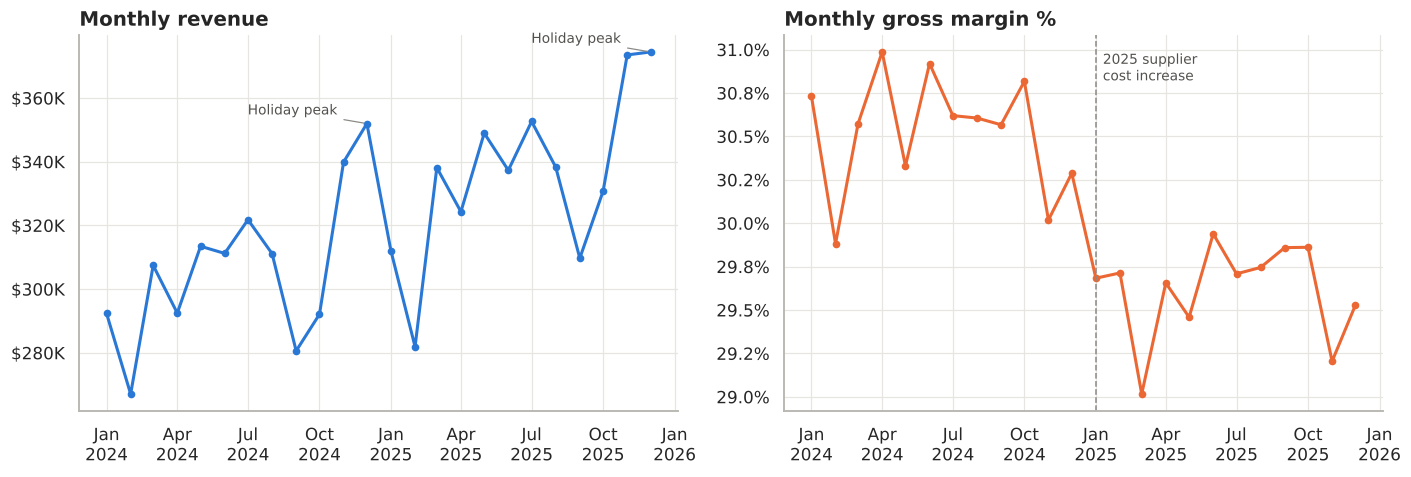

In [8]:
monthly = sales.groupby("month").agg(revenue=("revenue", "sum"), gp=("gross_profit", "sum"), txns=("txn_id", "nunique"))
monthly["margin"] = monthly.gp / monthly.revenue * 100
x = monthly.index.to_timestamp()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.plot(x, monthly.revenue, color=BLUE, lw=2, marker="o", ms=4)
ax.yaxis.set_major_formatter(usd)
ax.set_title("Monthly revenue")
for d in [pd.Timestamp("2024-12-01"), pd.Timestamp("2025-12-01")]:
    ax.annotate("Holiday peak", (d, monthly.revenue.loc[d.to_period("M")]), xytext=(-78, 6), textcoords="offset points",
                fontsize=9, color="#52514e", arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8))
ax = axes[1]
ax.plot(x, monthly.margin, color=ORANGE, lw=2, marker="o", ms=4)
ax.axvline(pd.Timestamp("2025-01-01"), color=GRAY, ls="--", lw=1)
ax.text(pd.Timestamp("2025-01-10"), monthly.margin.max(), "2025 supplier\ncost increase", fontsize=9, color="#52514e", va="top")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.set_title("Monthly gross margin %")
for a in axes:
    a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    a.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
fig.tight_layout()
plt.show()

### 💡 What the KPIs say
- **Revenue grew +9.2%**, driven by **more shoppers (+5.5% transactions)** and a **bigger ticket (+3.5% average basket)**.
- Items per basket stayed flat (10.2), so the basket increase is almost entirely **price**, matching the 3.5% shelf-price increase in 2025. Customers are not putting more in their carts.
- **Gross profit grew only +6.0%** because margin fell **0.9 points (30.5% → 29.6%)**. The margin chart shows a clear step down in January 2025: supplier costs rose ~5% while shelf prices rose only ~3.5%.
- **Takeaway:** the chain is growing, but it is absorbing cost inflation instead of passing it on. Recovering even half of the lost margin is worth roughly as much as another 1.5% of sales growth.

## 7. When Do Customers Shop? (Staffing & Traffic)

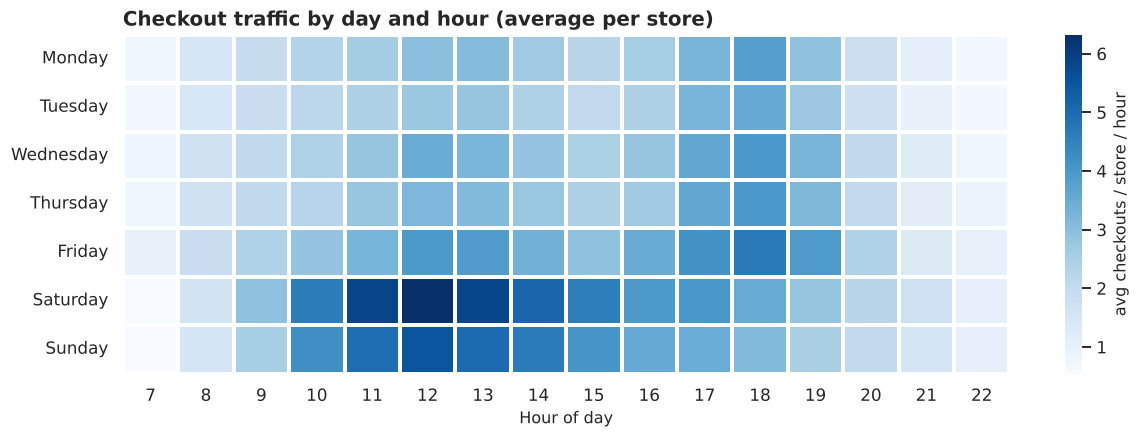

,avg daily revenue,avg daily checkouts,vs. weekly avg
dow,,,
Monday,8488.0,181.0,-20%
Tuesday,7953.0,170.0,-25%
Wednesday,9268.0,199.0,-12%
Thursday,9211.0,196.0,-13%
Friday,10934.0,233.0,+3%
Saturday,14929.0,284.0,+41%
Sunday,13223.0,252.0,+25%


In [9]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (baskets.assign(dow=baskets.txn_datetime.dt.day_name(), hour=baskets.txn_datetime.dt.hour)
        .pivot_table(index="dow", columns="hour", values="txn_id", aggfunc="count")
        .reindex(order))
heat = heat / sales.date.nunique() * 7 / stores.shape[0]          # avg receipts per store per hour
fig, ax = plt.subplots(figsize=(13, 4))
sns.heatmap(heat, cmap="Blues", linewidths=1.5, linecolor="white", cbar_kws={"label": "avg checkouts / store / hour"}, ax=ax)
ax.set_title("Checkout traffic by day and hour (average per store)")
ax.set_xlabel("Hour of day"); ax.set_ylabel("")
plt.show()

dow_tbl = (baskets.assign(dow=baskets.txn_datetime.dt.day_name(), date=baskets.txn_datetime.dt.normalize())
           .groupby(["dow", "date"]).agg(rev=("revenue", "sum"), n=("txn_id", "count")).groupby("dow").mean().reindex(order))
dow_tbl["vs. weekly avg"] = (dow_tbl.rev / dow_tbl.rev.mean() - 1).map("{:+.0%}".format)
dow_tbl.rename(columns={"rev": "avg daily revenue", "n": "avg daily checkouts"}).round(0)

In [10]:
daily = sales.groupby("date").revenue.sum()
top_days = daily.sort_values(ascending=False).head(6).rename("revenue").to_frame()
top_days["weekday"] = top_days.index.day_name()
top_days["vs. avg day"] = (top_days.revenue / daily[daily > 0].mean()).map("{:.1f}×".format)
print("Biggest sales days of the two years:")
top_days.style.format({"revenue": "${:,.0f}"})

Biggest sales days of the two years:


,revenue,weekday,vs. avg day
date,,,
2025-11-26 00:00:00,"$23,074",Wednesday,2.2×
2024-11-27 00:00:00,"$20,681",Wednesday,2.0×
2025-11-08 00:00:00,"$20,118",Saturday,1.9×
2025-12-27 00:00:00,"$18,744",Saturday,1.8×
2025-11-15 00:00:00,"$18,231",Saturday,1.7×
2025-11-22 00:00:00,"$18,094",Saturday,1.7×


### 💡 When customers shop
- **Saturday is the busiest day (+41% vs. the weekly average), followed by Sunday (+25%).** Tuesday is the quietest (−25%).
- Weekends peak **11 am–2 pm**; weekdays have a smaller lunch bump and a **5–7 pm after-work rush**. Before 9 am and after 8 pm, traffic is thin every day.
- **Thanksgiving Eve is the biggest day of the year (2.0–2.2× a normal day)**, ahead of Christmas week. November Saturdays also rank in the top 6.
- **Staffing implication:** shift cashier and stocking hours from Tuesday/Wednesday mornings into Saturday–Sunday midday and weekday 5–7 pm, and build Thanksgiving-week labor and inventory plans around a ~2× demand day.

### Anomaly detection: spotting disruptions automatically
A robust z-score on each store's daily revenue (compared with the same weekday in the surrounding weeks, using median and MAD so outliers can't hide themselves) flags days that are far outside normal — useful for catching outages, POS failures or data-feed gaps.

Unusual store-days (excluding known holidays):


,date,store_name,z,revenue
0,2024-02-28,Round Rock,4.8,2759.0
1,2024-07-07,Katy,11.7,7758.3
2,2024-07-08,Katy,-5.1,0.0
3,2024-07-09,Katy,-5.2,0.0
4,2024-07-10,Katy,-6.3,0.0
5,2024-08-04,Round Rock,4.8,3865.7
6,2025-02-18,Round Rock,4.7,2487.1
7,2025-03-01,Plano,5.5,5329.1
8,2025-03-02,Round Rock,6.9,4337.9
9,2025-07-20,Round Rock,4.8,4160.7


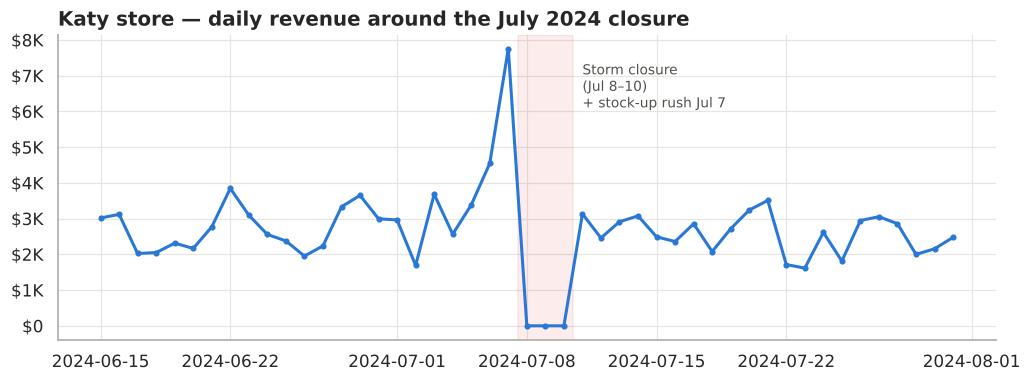

In [11]:
sd = sales.groupby(["store_name", "date"]).revenue.sum().unstack(0).asfreq("D").fillna(0)
# compare each day with the same weekday over the surrounding ±4 weeks (Saturdays vs Saturdays, etc.)
expected = pd.concat([g.rolling(9, center=True, min_periods=5).median()
                      for _, g in sd.groupby(sd.index.dayofweek)]).sort_index()
resid = sd - expected
scale = resid.abs().median() * 1.4826            # robust (MAD) spread of normal day-to-day noise, per store
z = resid / scale
flags = z.stack().rename("z").reset_index()
flags = flags[(flags.z.abs() > 4.5) & ~((flags.date.dt.month == 12) & flags.date.dt.day.isin([23, 24, 25, 31]))
              & ~flags.date.isin(pd.to_datetime(["2024-11-27", "2024-11-28", "2025-11-26", "2025-11-27", "2024-07-03", "2025-07-03"]))]
print("Unusual store-days (excluding known holidays):")
display(flags.sort_values("date").assign(revenue=lambda d: [sd.loc[r.date, r.store_name] for r in d.itertuples()])
        .round(1).reset_index(drop=True))

w = sd.loc["2024-06-15":"2024-07-31", "Katy"]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(w.index, w.values, color=BLUE, lw=2, marker="o", ms=3)
ax.axvspan(pd.Timestamp("2024-07-07 12:00"), pd.Timestamp("2024-07-10 12:00"), color=RED, alpha=0.10)
ax.text(pd.Timestamp("2024-07-11"), w.max() * 0.95, "Storm closure\n(Jul 8–10)\n+ stock-up rush Jul 7", fontsize=9, color="#52514e", va="top")
ax.yaxis.set_major_formatter(usd)
ax.set_title("Katy store — daily revenue around the July 2024 closure")
plt.show()

## 8. What Sells — and What Makes Money?

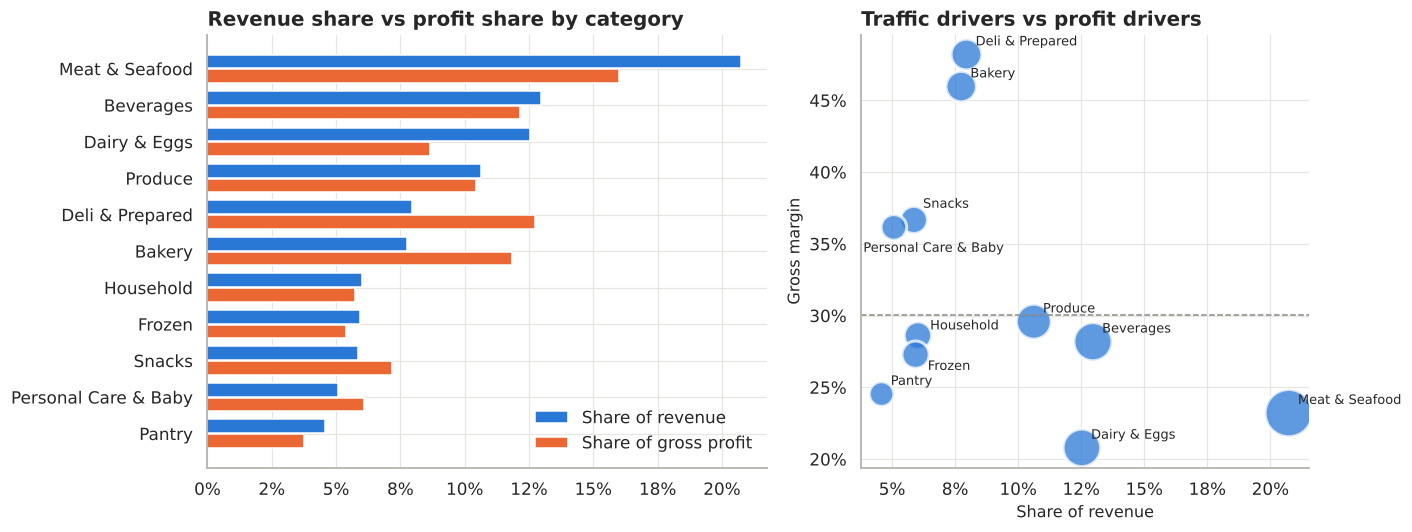

,revenue,gross_profit,margin,rev_share,gp_share
category,,,,,
Meat & Seafood,"$1,596,879","$370,568",23.2%,20.7%,16.0%
Beverages,"$998,787","$281,468",28.2%,13.0%,12.2%
Dairy & Eggs,"$964,937","$200,552",20.8%,12.5%,8.7%
Produce,"$818,093","$241,975",29.6%,10.6%,10.5%
Deli & Prepared,"$612,286","$295,072",48.2%,7.9%,12.7%
Bakery,"$596,303","$274,062",46.0%,7.7%,11.8%
Household,"$464,141","$132,791",28.6%,6.0%,5.7%
Frozen,"$456,916","$124,646",27.3%,5.9%,5.4%
Snacks,"$451,736","$165,626",36.7%,5.9%,7.2%


In [12]:
cat = (sales.groupby("category")
       .agg(revenue=("revenue", "sum"), gross_profit=("gross_profit", "sum"))
       .assign(margin=lambda d: d.gross_profit / d.revenue * 100,
               rev_share=lambda d: d.revenue / d.revenue.sum() * 100,
               gp_share=lambda d: d.gross_profit / d.gross_profit.sum() * 100)
       .sort_values("revenue", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
y = np.arange(len(cat))
ax.barh(y - 0.2, cat.rev_share, height=0.38, color=BLUE, label="Share of revenue")
ax.barh(y + 0.2, cat.gp_share, height=0.38, color=ORANGE, label="Share of gross profit")
ax.set_yticks(y, cat.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Revenue share vs profit share by category")
ax.legend(loc="lower right")
ax = axes[1]
ax.scatter(cat.rev_share, cat.margin, s=cat.revenue / cat.revenue.max() * 900 + 60, color=BLUE, alpha=0.75, edgecolor="white", lw=2)
nudge = {"Snacks": (6, 8), "Personal Care & Baby": (-20, -16), "Household": (8, 4), "Frozen": (8, -10)}
for name, r in cat.iterrows():
    ax.annotate(name, (r.rev_share, r.margin), xytext=nudge.get(name, (6, 6)), textcoords="offset points", fontsize=8.5)
ax.axhline(sales.gross_profit.sum() / sales.revenue.sum() * 100, color=GRAY, ls="--", lw=1)
ax.set_xlabel("Share of revenue"); ax.set_ylabel("Gross margin")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("Traffic drivers vs profit drivers")
fig.tight_layout()
plt.show()

cat.style.format({"revenue": "${:,.0f}", "gross_profit": "${:,.0f}", "margin": "{:.1f}%", "rev_share": "{:.1f}%", "gp_share": "{:.1f}%"})

Top 10 products by revenue:


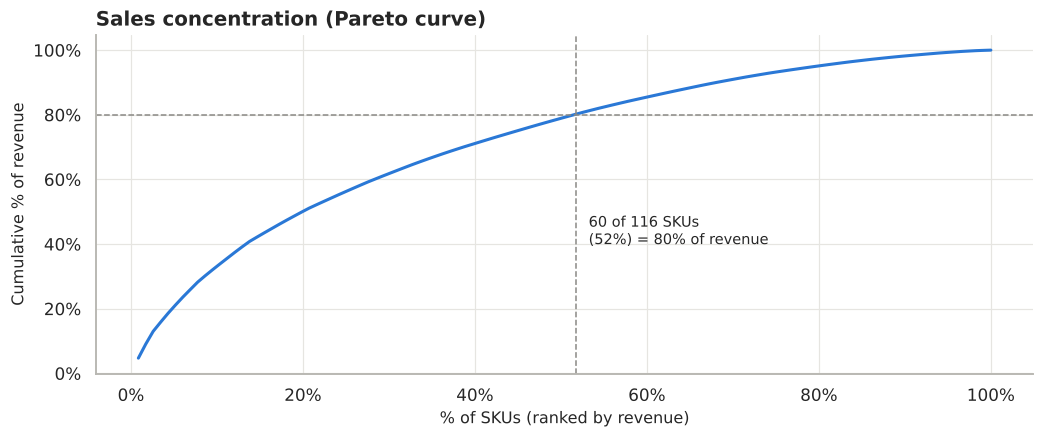

product_name,category,revenue,gp,units,margin
Whole Milk 1 Gal,Dairy & Eggs,"$362,936","$85,828","92,465",23.6%
Shrimp 2lb Frozen,Meat & Seafood,"$336,387","$85,816","21,406",25.5%
Ribeye Steak (lb),Meat & Seafood,"$302,724","$73,210","20,724",24.2%
Red Wine 750ml,Beverages,"$217,707","$55,216","18,156",25.4%
Chicken Nuggets 2lb,Frozen,"$210,667","$60,335","23,452",28.6%
Energy Drink 4pk,Beverages,"$197,135","$64,503","23,065",32.7%
Salmon Fillet (lb),Meat & Seafood,"$189,827","$46,692","17,583",24.6%
Fajita Beef (lb),Meat & Seafood,"$179,590","$36,287","20,564",20.2%
Beer 12pk,Beverages,"$177,549","$50,472","11,179",28.4%
Bacon 16oz,Meat & Seafood,"$149,864","$34,716","21,728",23.2%


In [13]:
# Pareto: how concentrated are sales across the 116 SKUs?
prod = sales.groupby(["product_name", "category"]).agg(revenue=("revenue", "sum"), gp=("gross_profit", "sum"),
                                                       units=("quantity", "sum")).reset_index().sort_values("revenue", ascending=False)
prod["cum_share"] = prod.revenue.cumsum() / prod.revenue.sum()
n80 = (prod.cum_share < 0.80).sum() + 1
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(np.arange(1, len(prod) + 1) / len(prod) * 100, prod.cum_share * 100, color=BLUE, lw=2)
ax.axhline(80, color=GRAY, ls="--", lw=1); ax.axvline(n80 / len(prod) * 100, color=GRAY, ls="--", lw=1)
ax.text(n80 / len(prod) * 100 + 1.5, 40, f"{n80} of {len(prod)} SKUs\n({n80/len(prod):.0%}) = 80% of revenue", fontsize=9.5)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlabel("% of SKUs (ranked by revenue)"); ax.set_ylabel("Cumulative % of revenue")
ax.set_title("Sales concentration (Pareto curve)")
plt.show()
print("Top 10 products by revenue:")
prod.head(10).assign(margin=lambda d: d.gp / d.revenue * 100).drop(columns="cum_share").style.format(
    {"revenue": "${:,.0f}", "gp": "${:,.0f}", "units": "{:,.0f}", "margin": "{:.1f}%"}).hide(axis="index")

### 💡 Traffic drivers vs. profit drivers
- **Meat & Seafood is the #1 revenue category (20.7% of sales) but earns only 23% margin**, so its share of profit drops to 16.0%. **Dairy & Eggs** is the extreme case: 12.5% of sales, 8.7% of profit, at a 21% margin.
- **Deli & Prepared (48% margin) and Bakery (46%) punch far above their weight:** together they are 15.7% of sales but **24.6% of gross profit**.
- Whole milk is the single biggest product by revenue, a classic low-margin "traffic driver" that brings customers in.
- Sales are spread fairly evenly: **60 of 116 SKUs (52%) make up 80% of revenue**. That is typical of grocery, where breadth of assortment matters.
- **Takeaway:** keep milk, eggs and meat priced competitively to drive trips, and **earn the margin back through placement**. Put Deli and Bakery on the path between the meat counter and dairy, and cross-promote prepared foods.

## 9. Store Performance

In [14]:
st = (sales.groupby(["store_name", "year"])
      .agg(revenue=("revenue", "sum"), gp=("gross_profit", "sum"), txns=("txn_id", "nunique"), sq_ft=("sq_ft", "first"))
      .unstack("year"))
store_tbl = pd.DataFrame({
    "Revenue 2025": st[("revenue", 2025)],
    "YoY Growth": st[("revenue", 2025)] / st[("revenue", 2024)] - 1,
    "Gross Margin": st[("gp", 2025)] / st[("revenue", 2025)],
    "Avg Basket": st[("revenue", 2025)] / st[("txns", 2025)],
    "Checkouts / Day": st[("txns", 2025)] / 364,
    "Sales per Sq Ft (index)": st[("revenue", 2025)] / st[("sq_ft", 2025)],
})
store_tbl["Sales per Sq Ft (index)"] = store_tbl["Sales per Sq Ft (index)"] / store_tbl["Sales per Sq Ft (index)"].mean() * 100
store_tbl = store_tbl.sort_values("Revenue 2025", ascending=False)
member_share = sales[sales.year == 2025].groupby("store_name").apply(lambda g: g.loc[g.is_member, "revenue"].sum() / g.revenue.sum())
store_tbl["Member Sales %"] = member_share
store_tbl.style.format({"Revenue 2025": "${:,.0f}", "YoY Growth": "{:+.1%}", "Gross Margin": "{:.1%}", "Avg Basket": "${:.2f}",
                        "Checkouts / Day": "{:.0f}", "Sales per Sq Ft (index)": "{:.0f}", "Member Sales %": "{:.1%}"}) \
    .background_gradient(subset=["Sales per Sq Ft (index)"], cmap="Blues")

,Revenue 2025,YoY Growth,Gross Margin,Avg Basket,Checkouts / Day,Sales per Sq Ft (index),Member Sales %
store_name,,,,,,,
Katy,"$1,016,827",+7.3%,29.6%,$49.93,56,102,48.5%
Plano,"$928,781",+11.0%,29.6%,$49.81,51,103,48.2%
Round Rock,"$831,941",+8.1%,29.6%,$49.69,46,117,47.0%
Stone Oak,"$674,451",+12.9%,29.6%,$49.09,38,84,46.0%
Keller,"$570,194",+7.6%,29.7%,$49.66,32,93,49.7%


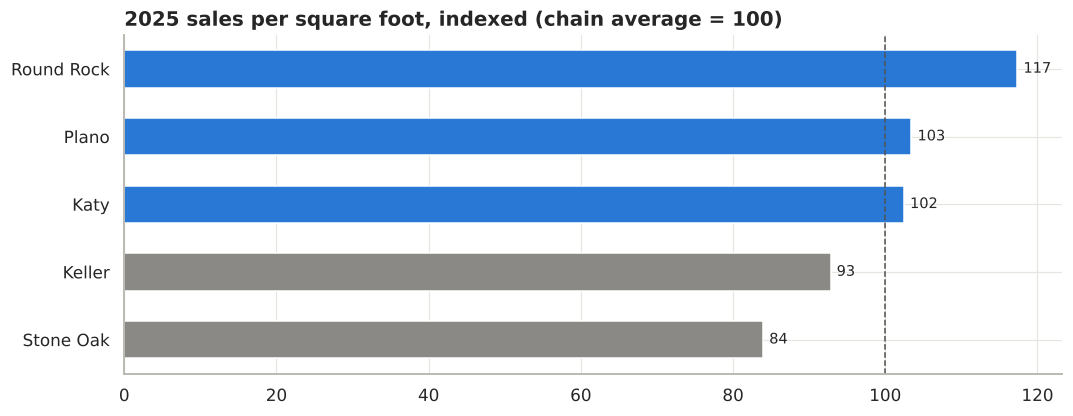

In [15]:
fig, ax = plt.subplots(figsize=(11, 4))
s = store_tbl.sort_values("Sales per Sq Ft (index)")
bars = ax.barh(s.index, s["Sales per Sq Ft (index)"], color=[BLUE if v >= 100 else GRAY for v in s["Sales per Sq Ft (index)"]], height=0.55)
ax.bar_label(bars, labels=[f"{v:.0f}" for v in s["Sales per Sq Ft (index)"]], padding=4, fontsize=9.5)
ax.axvline(100, color="#52514e", ls="--", lw=1)
ax.set_title("2025 sales per square foot, indexed (chain average = 100)")
plt.show()

### 💡 Store performance
- **Katy is the largest store by revenue, but Round Rock uses its space best:** 17% above the chain average in sales per square foot.
- **Stone Oak is the fastest-growing store (+12.9% YoY) but the least productive (index 84).** It is gaining customers but still under-uses its floor space. That makes it the best candidate for a layout or assortment review rather than more marketing spend.
- **Plano combines strong growth (+11.0%) with above-average productivity**, the healthiest profile in the chain.
- Margins and basket sizes are nearly identical across stores (~29.6%, ~$49–50). The differences come from **traffic**, not pricing or mix.
- Anomaly detection caught the **July 2024 Katy closure** automatically: a stock-up rush the day before the storm (11.7 robust standard deviations above normal), then three days of zero sales. The few smaller flags are worth a quick check for local events or data-feed issues.

## 10. Customer Analytics — Loyalty Members

### 10.1 Members vs. walk-in shoppers

In [16]:
mv = baskets.groupby("is_member").agg(receipts=("txn_id", "count"), avg_basket=("revenue", "mean"),
                                       items=("items", "mean"), share=("revenue", "sum"))
mv["share"] = mv.share / mv.share.sum()
mv.index = mv.index.map({True: "Loyalty member", False: "Walk-in (no card)"})
mv.style.format({"receipts": "{:,.0f}", "avg_basket": "${:.2f}", "items": "{:.1f}", "share": "{:.1%}"})

,receipts,avg_basket,items,share
is_member,,,,
Walk-in (no card),"101,926",$39.55,8.3,52.3%
Loyalty member,"55,790",$65.84,13.7,47.7%


### 10.2 RFM segmentation
Every member is scored 1–5 on **R**ecency (days since last visit), **F**requency (visits) and **M**onetary value (spend) over the last 12 months, then grouped into actionable segments.

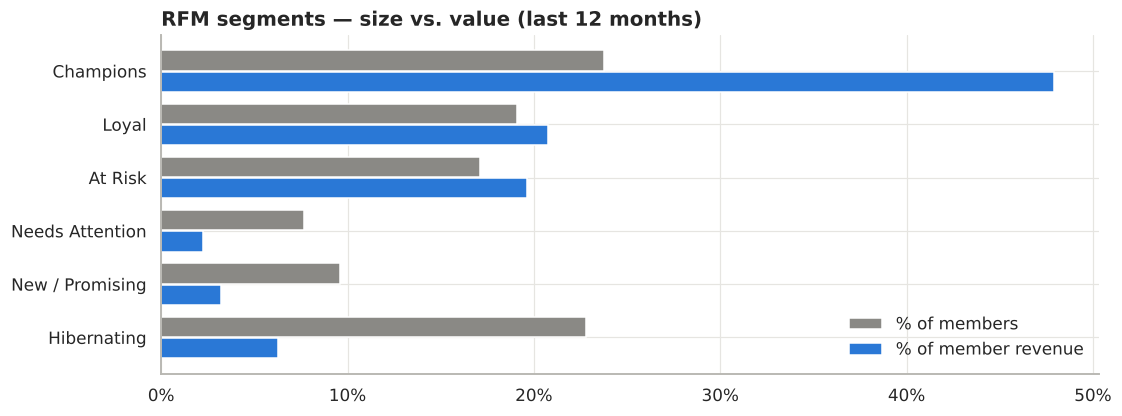

,members,avg_recency_days,avg_visits,avg_spend,% members,% member revenue
segment,,,,,,
Champions,494,7,28.0,"$1,869",23.8%,47.9%
Loyal,397,26,15.1,"$1,006",19.1%,20.7%
At Risk,355,167,15.8,"$1,065",17.1%,19.6%
Needs Attention,159,38,4.1,$274,7.7%,2.3%
New / Promising,199,8,4.6,$309,9.6%,3.2%
Hibernating,473,240,3.8,$254,22.8%,6.2%


In [17]:
snapshot = pd.Timestamp("2026-01-01")
last12 = baskets[(baskets.is_member) & (baskets.txn_datetime >= snapshot - pd.DateOffset(years=1))]
rfm = last12.groupby("customer_id").agg(recency=("txn_datetime", lambda s: (snapshot - s.max()).days),
                                        frequency=("txn_id", "count"), monetary=("revenue", "sum"))
rfm["R"] = pd.qcut(rfm.recency, 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm.frequency.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm.monetary, 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(r):
    if r.R >= 4 and r.F >= 4: return "Champions"
    if r.R >= 3 and r.F >= 3: return "Loyal"
    if r.R >= 4 and r.F <= 2: return "New / Promising"
    if r.R <= 2 and r.F >= 3: return "At Risk"
    if r.R <= 2 and r.F <= 2: return "Hibernating"
    return "Needs Attention"
rfm["segment"] = rfm.apply(segment, axis=1)

seg = rfm.groupby("segment").agg(members=("R", "size"), avg_recency_days=("recency", "mean"),
                                 avg_visits=("frequency", "mean"), avg_spend=("monetary", "mean"), total_spend=("monetary", "sum"))
seg["% members"] = seg.members / seg.members.sum()
seg["% member revenue"] = seg.total_spend / seg.total_spend.sum()
seg = seg.sort_values("total_spend", ascending=False)
seg_order = ["Champions", "Loyal", "At Risk", "Needs Attention", "New / Promising", "Hibernating"]
seg = seg.reindex([s for s in seg_order if s in seg.index])

fig, ax = plt.subplots(figsize=(11, 4))
yy = np.arange(len(seg))
ax.barh(yy - 0.2, seg["% members"] * 100, height=0.38, color=GRAY, label="% of members")
ax.barh(yy + 0.2, seg["% member revenue"] * 100, height=0.38, color=BLUE, label="% of member revenue")
ax.set_yticks(yy, seg.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_title("RFM segments — size vs. value (last 12 months)")
ax.legend(loc="lower right")
plt.show()
seg.drop(columns="total_spend").style.format({"members": "{:,.0f}", "avg_recency_days": "{:.0f}", "avg_visits": "{:.1f}",
                                              "avg_spend": "${:,.0f}", "% members": "{:.1%}", "% member revenue": "{:.1%}"})

### 10.3 Cohort retention — how quickly do new members drop off?
Members are grouped by signup month; each cell shows the share of that cohort that made at least one purchase *k* months after joining. (Month 0 is a partial month — members join on different days of the month.)

Average retention curve: M1: 76% → M3: 67% → M6: 52% → M9: 44% → M12: 34%


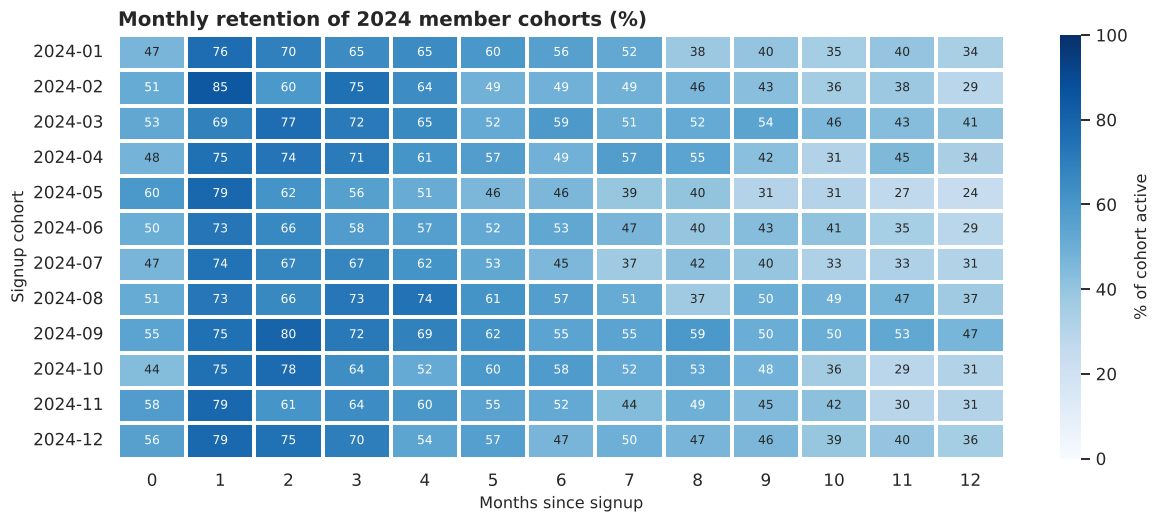

In [18]:
mem = baskets[baskets.is_member].merge(customers[["customer_id", "signup_date"]], on="customer_id")
mem = mem[(mem.signup_date >= "2024-01-01") & (mem.signup_date < "2025-01-01")]
mem["cohort"] = mem.signup_date.dt.to_period("M")
mem["age_m"] = (mem.txn_datetime.dt.to_period("M") - mem.cohort).apply(lambda p: p.n)
cohort_size = customers[(customers.signup_date >= "2024-01-01") & (customers.signup_date < "2025-01-01")] \
    .groupby(customers.signup_date.dt.to_period("M")).size()
ret = mem[mem.age_m.between(0, 12)].groupby(["cohort", "age_m"]).customer_id.nunique().unstack()
ret = ret.div(cohort_size, axis=0)

fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(ret * 100, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, linewidths=1.5, linecolor="white",
            cbar_kws={"label": "% of cohort active"}, annot_kws={"fontsize": 8}, ax=ax)
ax.set_title("Monthly retention of 2024 member cohorts (%)")
ax.set_xlabel("Months since signup"); ax.set_ylabel("Signup cohort")
plt.show()
avg_curve = ret.mean()
print("Average retention curve:", " → ".join(f"M{k}: {v:.0%}" for k, v in avg_curve.items() if k in [1, 3, 6, 9, 12]))

### 💡 Customer insights
- **Loyalty members are only 35% of receipts but 48% of revenue.** Their average basket is **$65.84 vs. $39.55** for walk-in shoppers (+66%), with 13.7 vs. 8.3 items.
- **Champions (24% of active members) generate 48% of member revenue**, visiting about every 13 days.
- **The "At Risk" segment is the urgent one:** 355 members who used to shop as often as Loyal members (~16 visits a year, ~$1,065 each) but have not been in for **~167 days on average**. They hold **20% of member revenue**.
- **Retention:** 76% of new members shop again in their first full month, but only **52% are still active at month 6 and 34% at month 12**. The steepest drop happens between months 3 and 6.
- The SQL analysis (Q4) shows **45% of repeat visits happen within a week and 88% within a month**. A member who has not shopped in 30+ days is already unusual.
- **Takeaway:** (1) launch a win-back offer for At Risk members, triggered automatically at 30–45 days without a visit; (2) build a 90-day onboarding journey for new members to close the month 3–6 gap; (3) push walk-in shoppers to join at checkout, since members spend 66% more per trip.

## 11. Market Basket Analysis — Which Products Sell Together?

For every pair of products I compute:
- **Support** — share of all baskets containing both products
- **Confidence (A→B)** — of baskets with A, the share that also contain B
- **Lift** — how much more often they appear together than if purchases were independent (lift > 1 = real affinity)

In [19]:
basket_prod = sales[["txn_id", "product_id"]].drop_duplicates()
top_ids = basket_prod.product_id.value_counts().index           # all SKUs (116 is small enough)
X = pd.crosstab(basket_prod.txn_id, basket_prod.product_id).reindex(columns=top_ids).to_numpy(dtype=np.float32)
n_b = X.shape[0]
co = X.T @ X                                                     # co-occurrence counts
supp = np.diag(co) / n_b
id_name = products.set_index("product_id").product_name

i, j = np.triu_indices(len(top_ids), k=1)
rules = pd.DataFrame({"A": id_name[top_ids[i]].values, "B": id_name[top_ids[j]].values,
                      "support": co[i, j] / n_b, "supp_A": supp[i], "supp_B": supp[j]})
rules["lift"] = rules.support / (rules.supp_A * rules.supp_B)
rules["conf_A→B"] = rules.support / rules.supp_A
rules["conf_B→A"] = rules.support / rules.supp_B
rules = rules[rules.support >= 0.003].sort_values("lift", ascending=False)

print(f"Baskets analysed: {n_b:,}")
rules.head(12)[["A", "B", "support", "conf_A→B", "conf_B→A", "lift"]].style.format(
    {"support": "{:.2%}", "conf_A→B": "{:.0%}", "conf_B→A": "{:.0%}", "lift": "{:.1f}×"}).hide(axis="index")

Baskets analysed: 157,716


A,B,support,conf_A→B,conf_B→A,lift
Pasta Sauce 24oz,Spaghetti 16oz,1.88%,49%,51%,13.2×
Baby Wipes 3pk,Diapers Size 3,1.25%,34%,41%,11.4×
Peanut Butter 16oz,Grape Jelly 18oz,2.50%,41%,45%,7.5×
Ground Beef 80/20 (lb),Taco Seasoning,1.11%,23%,35%,7.1×
Hot Dog Buns 8ct,Hot Dogs 8ct,2.56%,34%,54%,7.1×
Flour Tortillas 20ct,Fajita Beef (lb),3.30%,42%,49%,6.3×
Ground Beef 80/20 (lb),Hamburger Buns 8ct,1.46%,30%,31%,6.2×
BBQ Sauce 18oz,Brisket (lb),1.63%,27%,36%,5.9×
Coffee Creamer 32oz,Ground Coffee 12oz,2.61%,33%,41%,5.2×
Tortilla Chips,Salsa 16oz,3.59%,41%,42%,4.8×


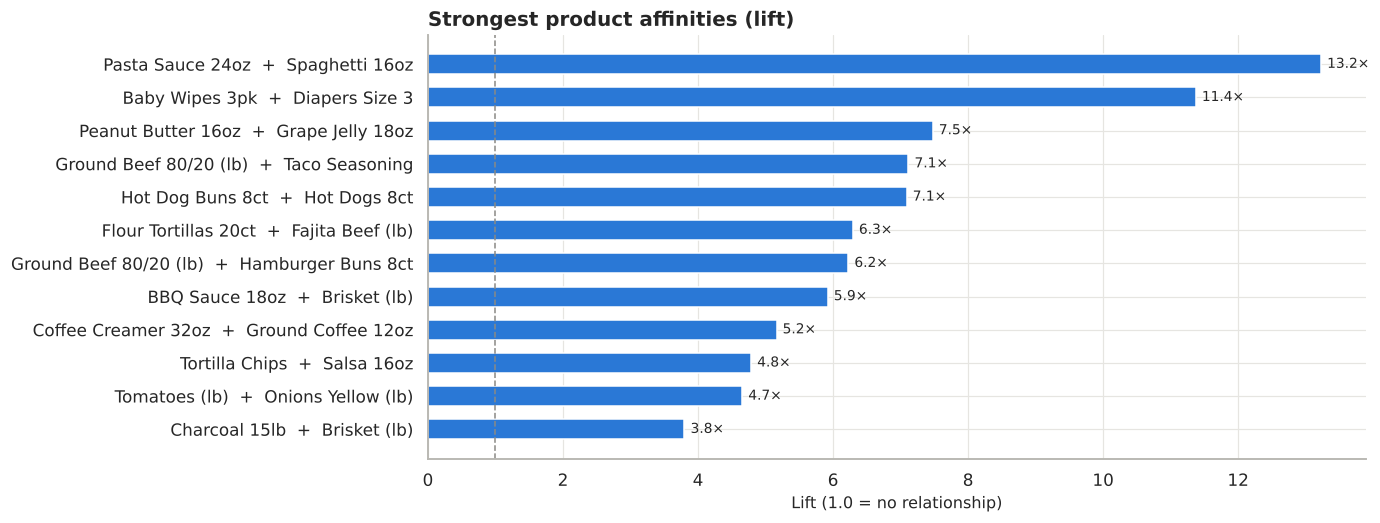

In [20]:
top = rules.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(top.A + "  +  " + top.B, top.lift, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.1f}×" for v in top.lift], padding=4, fontsize=9)
ax.axvline(1, color=GRAY, ls="--", lw=1)
ax.set_title("Strongest product affinities (lift)")
ax.set_xlabel("Lift (1.0 = no relationship)")
plt.show()

### 💡 Product affinities
- The strongest pairs are **meal solutions**: Spaghetti + Pasta Sauce (**13.2× lift**, ~50% of buyers of one also buy the other), Diapers + Baby Wipes (11.4×), Peanut Butter + Jelly (7.5×).
- **Texas-specific pairs stand out:** Fajita Beef + Flour Tortillas (49% of fajita buyers also buy tortillas), Brisket + BBQ Sauce + Charcoal, and Tortilla Chips + Salsa (41% attach rate).
- **Takeaway — three concrete actions:**
  1. **Cross-merchandise**: place tortillas and fajita seasoning in the meat department; put salsa on a display next to chips.
  2. **Bundle deals** instead of single-item discounts, e.g. "Fajita Night" (beef + tortillas) or "Pasta Night" (spaghetti + sauce). Discount the cheap item, not the expensive one.
  3. **Attach-rate gaps are revenue**: ~59% of chip buyers *don't* buy salsa. Moving that attach rate by a few points is pure incremental sales.

## 12. Promotion Effectiveness — Do Weekly Deals Pay Off?
For each promoted SKU-week, I compare units and gross profit against the same SKU's average **non-promo** week at the same store chain, giving unit lift and incremental profit.

,promo_weeks,avg_unit_lift,avg_incremental_gp,share_losing_money
discount_pct,,,,
15% off,251,+59%,$-40,72%
20% off,244,+87%,$-56,74%
25% off,290,+119%,$-91,84%
30% off,265,+147%,$-138,91%


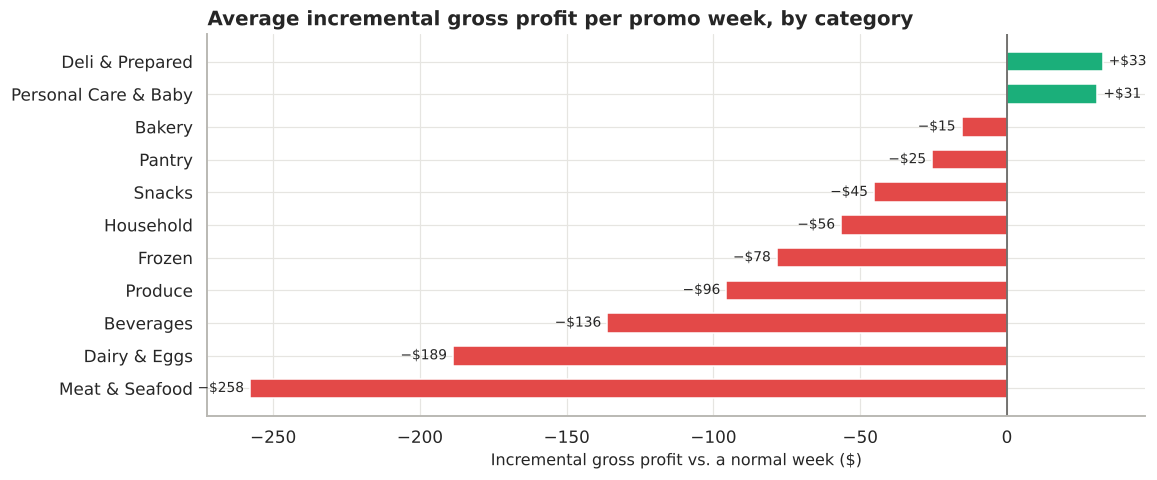

,promo_weeks,median_unit_lift,avg_incremental_gp,share_losing_money
category,,,,
Meat & Seafood,115,+86%,$-258,100%
Dairy & Eggs,93,+67%,$-189,100%
Beverages,89,+89%,$-136,100%
Produce,131,+70%,$-96,98%
Frozen,70,+135%,$-78,91%
Household,82,+176%,$-56,76%
Snacks,90,+87%,$-45,91%
Pantry,152,+150%,$-25,78%
Bakery,92,+79%,$-15,53%


In [21]:
sales["week"] = sales.txn_datetime.dt.to_period("W-SUN").dt.start_time
wk = sales.groupby(["product_id", "week"]).agg(units=("quantity", "sum"), gp=("gross_profit", "sum"),
                                               rev=("revenue", "sum"), promo=("on_promo", "max")).reset_index()
# fill weeks with zero sales so the baseline is fair
full = pd.MultiIndex.from_product([products.product_id, sorted(sales.week.unique())], names=["product_id", "week"])
wk = wk.set_index(["product_id", "week"]).reindex(full, fill_value=0).reset_index()
wk = wk.merge(promos.rename(columns={"week_start": "week"}), on=["product_id", "week"], how="left")
wk["promo"] = wk.discount_pct.notna()
base = wk[~wk.promo].groupby("product_id").agg(base_units=("units", "mean"), base_gp=("gp", "mean"))
pw = wk[wk.promo].merge(base, on="product_id").merge(products[["product_id", "product_name", "category"]], on="product_id")
pw["unit_lift"] = pw.units / pw.base_units - 1
pw["incr_gp"] = pw.gp - pw.base_gp

by_disc = pw.groupby("discount_pct").agg(promo_weeks=("units", "size"), avg_unit_lift=("unit_lift", "median"),
                                         avg_incremental_gp=("incr_gp", "mean"), share_losing_money=("incr_gp", lambda s: (s < 0).mean()))
by_disc.index = by_disc.index.map("{:.0%} off".format)
display(by_disc.style.format({"avg_unit_lift": "{:+.0%}", "avg_incremental_gp": "${:+,.0f}", "share_losing_money": "{:.0%}"}))

by_cat = pw.groupby("category").agg(promo_weeks=("units", "size"), median_unit_lift=("unit_lift", "median"),
                                    avg_incremental_gp=("incr_gp", "mean"), share_losing_money=("incr_gp", lambda s: (s < 0).mean())) \
           .sort_values("avg_incremental_gp")

fig, ax = plt.subplots(figsize=(11, 4.5))
colors = [RED if v < 0 else AQUA for v in by_cat.avg_incremental_gp]
bars = ax.barh(by_cat.index, by_cat.avg_incremental_gp, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{'+' if v >= 0 else '−'}${abs(v):,.0f}" for v in by_cat.avg_incremental_gp], padding=4, fontsize=9)
ax.axvline(0, color="#52514e", lw=1)
ax.set_title("Average incremental gross profit per promo week, by category")
ax.set_xlabel("Incremental gross profit vs. a normal week ($)")
plt.show()
by_cat.style.format({"median_unit_lift": "{:+.0%}", "avg_incremental_gp": "${:+,.0f}", "share_losing_money": "{:.0%}"})

### 💡 Promotion effectiveness
- Promotions **do move volume**: units rise **+59% at 15% off** and **+147% at 30% off**.
- But **about 80% of promo weeks earn less gross profit than a normal week.** Deeper discounts lose more: on average **−$40 per SKU-week at 15% off vs. −$138 at 30% off**.
- The damage is concentrated in **low-margin categories**. **Meat & Seafood, Dairy & Eggs and Beverages lost money in every single promo week**: a 25% discount on a 21–28% margin item gives away almost the whole margin.
- **Only Deli & Prepared and Personal Care & Baby (36–48% margins) are profitable on average.** They have enough margin to fund the discount, and their volume response is strong.
- **Caveat:** this measures the promoted item only. A promo can still pay off if it brings in extra trips or bigger baskets (a "halo" effect), so the next step is a controlled test that measures basket-level impact.
- **Takeaway:** cap discounts at 15–20% on low-margin categories, move promo dollars toward high-margin categories and bundles (see the basket analysis), and require a measured test before running any 25–30% discount again.

## 13. SQL Analysis
The same questions answered in SQL — the way an analyst would query a company data warehouse. The cleaned tables are loaded into an in-memory SQLite database.

In [22]:
con = sqlite3.connect(":memory:")
items.to_sql("transaction_items", con, index=False)
t = transactions.copy(); t["txn_datetime"] = t.txn_datetime.astype(str)
t.to_sql("transactions", con, index=False)
products.to_sql("products", con, index=False)
stores.drop(columns="opened").to_sql("stores", con, index=False)
customers.assign(signup_date=customers.signup_date.astype(str)).to_sql("customers", con, index=False)

def sql(q):
    return pd.read_sql(q, con)
print("Tables:", sql("SELECT name FROM sqlite_master WHERE type='table'").name.tolist())

Tables: ['transaction_items', 'transactions', 'products', 'stores', 'customers']


**Q1. Monthly revenue with month-over-month and year-over-year growth** (`LAG` window function)

In [23]:
sql("""
WITH monthly AS (
    SELECT substr(t.txn_datetime, 1, 7)                                   AS month,
           ROUND(SUM(i.quantity * i.unit_price * (1 - i.discount_pct)), 0) AS revenue
    FROM transaction_items i
    JOIN transactions t ON t.txn_id = i.txn_id
    GROUP BY 1
)
SELECT month,
       revenue,
       ROUND(100.0 * (revenue - LAG(revenue, 1)  OVER (ORDER BY month)) / LAG(revenue, 1)  OVER (ORDER BY month), 1) AS mom_growth_pct,
       ROUND(100.0 * (revenue - LAG(revenue, 12) OVER (ORDER BY month)) / LAG(revenue, 12) OVER (ORDER BY month), 1) AS yoy_growth_pct
FROM monthly
ORDER BY month DESC
LIMIT 12;
""")

,month,revenue,mom_growth_pct,yoy_growth_pct
0,2025-12,374472.0,0.2,6.4
1,2025-11,373542.0,12.9,9.9
2,2025-10,330786.0,6.8,13.2
3,2025-09,309724.0,-8.5,10.4
4,2025-08,338328.0,-4.1,8.7
5,2025-07,352648.0,4.5,9.6
6,2025-06,337322.0,-3.3,8.4
7,2025-05,348988.0,7.6,11.3
8,2025-04,324309.0,-4.1,10.9
9,2025-03,338157.0,19.9,10.0


**Q2. Top 3 products in each category by 2025 gross profit** (`RANK() OVER (PARTITION BY ...)`)

In [24]:
sql("""
WITH product_gp AS (
    SELECT p.category, p.product_name,
           SUM(i.quantity * (i.unit_price * (1 - i.discount_pct) - i.unit_cost)) AS gross_profit
    FROM transaction_items i
    JOIN transactions t ON t.txn_id = i.txn_id
    JOIN products     p ON p.product_id = i.product_id
    WHERE t.txn_datetime >= '2025-01-01'
    GROUP BY 1, 2
), ranked AS (
    SELECT *, RANK() OVER (PARTITION BY category ORDER BY gross_profit DESC) AS rnk
    FROM product_gp
)
SELECT category, rnk, product_name, ROUND(gross_profit, 0) AS gross_profit_2025
FROM ranked
WHERE rnk <= 3
ORDER BY category, rnk;
""").head(15)

,category,rnk,product_name,gross_profit_2025
0,Bakery,1,Birthday Cake 8in,34378.0
1,Bakery,2,Kolaches 6ct,24346.0
2,Bakery,3,Croissants 4ct,22368.0
3,Beverages,1,Energy Drink 4pk,33057.0
4,Beverages,2,Red Wine 750ml,28902.0
5,Beverages,3,Beer 12pk,25905.0
6,Dairy & Eggs,1,Whole Milk 1 Gal,44438.0
7,Dairy & Eggs,2,Greek Yogurt 32oz,13409.0
8,Dairy & Eggs,3,Large Eggs 12ct,8549.0
9,Deli & Prepared,1,Tamales 12ct,31880.0


**Q3. Store scorecard: revenue, growth, and rank** (multiple CTEs + conditional aggregation)

In [25]:
sql("""
WITH store_year AS (
    SELECT s.store_name, s.sq_ft,
           SUM(CASE WHEN t.txn_datetime <  '2025-01-01' THEN i.quantity * i.unit_price * (1 - i.discount_pct) END) AS rev_2024,
           SUM(CASE WHEN t.txn_datetime >= '2025-01-01' THEN i.quantity * i.unit_price * (1 - i.discount_pct) END) AS rev_2025
    FROM transaction_items i
    JOIN transactions t ON t.txn_id = i.txn_id
    JOIN stores       s ON s.store_id = t.store_id
    GROUP BY 1, 2
)
SELECT store_name,
       ROUND(rev_2025, 0)                               AS revenue_2025,
       ROUND(100.0 * (rev_2025 - rev_2024) / rev_2024, 1) AS yoy_growth_pct,
       ROUND(100 * (rev_2025 / sq_ft) / AVG(rev_2025 / sq_ft) OVER (), 0) AS sqft_productivity_index,
       RANK() OVER (ORDER BY rev_2025 / sq_ft DESC)     AS productivity_rank
FROM store_year
ORDER BY productivity_rank;
""")

,store_name,revenue_2025,yoy_growth_pct,sqft_productivity_index,productivity_rank
0,Round Rock,831941.0,8.1,117.0,1
1,Plano,928781.0,11.0,103.0,2
2,Katy,1016827.0,7.3,102.0,3
3,Keller,570194.0,7.6,93.0,4
4,Stone Oak,674451.0,12.9,84.0,5


**Q4. How fast do members come back?** Days between consecutive visits per member (`LAG ... PARTITION BY customer`)

In [26]:
sql("""
WITH visits AS (
    SELECT customer_id, txn_datetime,
           julianday(txn_datetime) - julianday(LAG(txn_datetime) OVER (PARTITION BY customer_id ORDER BY txn_datetime)) AS days_since_prev
    FROM transactions
    WHERE customer_id IS NOT NULL
)
SELECT CASE WHEN days_since_prev <= 7  THEN '1) within 1 week'
            WHEN days_since_prev <= 14 THEN '2) 1–2 weeks'
            WHEN days_since_prev <= 30 THEN '3) 2–4 weeks'
            WHEN days_since_prev <= 60 THEN '4) 1–2 months'
            ELSE                            '5) 2+ months' END   AS gap_since_last_visit,
       COUNT(*)                                                  AS visits,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1)        AS pct_of_repeat_visits
FROM visits
WHERE days_since_prev IS NOT NULL
GROUP BY 1
ORDER BY 1;
""")

,gap_since_last_visit,visits,pct_of_repeat_visits
0,1) within 1 week,23729,45.0
1,2) 1–2 weeks,11421,21.6
2,3) 2–4 weeks,11086,21.0
3,4) 1–2 months,5014,9.5
4,5) 2+ months,1520,2.9


**Q5. Payment mix and basket size** — useful for checkout-lane and SNAP/EBT planning

In [27]:
sql("""
WITH receipt AS (
    SELECT t.txn_id, t.payment_method, SUM(i.quantity * i.unit_price * (1 - i.discount_pct)) AS basket
    FROM transactions t JOIN transaction_items i ON i.txn_id = t.txn_id
    GROUP BY 1, 2
)
SELECT payment_method,
       COUNT(*)                                         AS receipts,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_receipts,
       ROUND(AVG(basket), 2)                            AS avg_basket
FROM receipt
GROUP BY 1
ORDER BY receipts DESC;
""")

,payment_method,receipts,pct_receipts,avg_basket
0,Credit/Debit,98242,62.3,50.29
1,Cash,24091,15.3,43.73
2,Mobile Wallet,22363,14.2,45.30
3,SNAP/EBT,13020,8.3,53.53


## 14. Summary & Recommendations

| # | Finding | Recommendation | Expected impact |
|---|---|---|---|
| 1 | Margin fell 0.9 pts because 2025 supplier costs (+5%) outpaced shelf prices (+3.5%) | Targeted price review on low-elasticity items; renegotiate top-10 supplier costs | Recover margin, protect profit growth |
| 2 | ~80% of promo weeks lose gross profit; Meat, Dairy and Beverage promos lose money every time | Cap low-margin discounts at 15–20%; shift promo budget to Deli, Bakery, Personal Care and bundles | Turn promo spend from a cost into a profit driver |
| 3 | 355 "At Risk" members hold 20% of member revenue and haven't shopped in ~5 months | Automated win-back offer at 30–45 days without a visit | Re-activate high-value customers |
| 4 | New-member retention drops from 67% (month 3) to 52% (month 6) | 90-day onboarding journey (personalized offers on 2nd–4th visit) | Lift 12-month retention above 34% |
| 5 | Members spend 66% more per trip than walk-ins, but are only 35% of receipts | Sign-up incentive at checkout; train cashiers to offer the card | Grow the high-value customer base |
| 6 | Strong meal-solution affinities (fajitas, pasta, BBQ) | Cross-merchandise and run bundle deals instead of single-item discounts | Higher basket size and attach rate |
| 7 | Saturday (+41%) and weekday 5–7 pm are the peaks; Tuesday is 25% below average | Re-balance labor hours toward peak windows | Shorter lines at peaks, lower labor cost off-peak |
| 8 | Stone Oak is the fastest-growing but least space-efficient store | Layout and assortment review at Stone Oak, using Round Rock as the benchmark | Raise sales per sq ft toward chain average |

### Limitations & next steps
- The data is simulated, so findings illustrate the **method**; on a real POS feed the same notebook runs unchanged once the five tables are loaded.
- Promo analysis looks only at the promoted SKU. Next step: measure basket-level halo and cannibalization with a test-vs-control store design.
- Next steps: a **demand forecast** by store and category for staffing and ordering, and a **Power BI / Tableau dashboard** for store managers.

---
*Thanks for reading! Feedback and questions are welcome on [LinkedIn](https://www.linkedin.com/in/abrar313).*